# ISA 591 · Module 6 · Class 1
## Logistic Regression: Probabilities, Odds, and Log-Odds

**Goal:** Understand how a binary response (0/1) can be modeled as a probability, fit a simple logistic regression, and interpret odds.

**How to use:** Run the code cells in order. When you see **Your turn**, change a value or write a short answer before continuing.

### 1. Why logistic regression?

Suppose `default = 1` means a borrower defaults, and `default = 0` means the borrower does not default. A straight line can predict numbers below 0 or above 1; **probabilities must stay between 0 and 1**.

The logistic (sigmoid) transformation is

$$p=\frac{1}{1+e^{-z}}, \qquad z=\beta_0+\beta_1x.$$

The value $z$ can be any real number, but $p$ is between 0 and 1.

In [ ]:
## LOGISTIC REGRESSION
#### used for classification (binary response)
#### we assume encoding of y = {1: level of interest, 0: other level}
#### we use the LOGIT TRANSFORMATION to change from an unconstrained prediction (yhat) to a probability with 0 and 1 limit

In [5]:
## LOGIT TRANSFORM

#### formula 1: p = e^z / (1+e^z) ----- given a z, p will always be between 0 and 1
z = -12   ## we assume z is the result of LINEAR REGRESSION output
print(f'For a value of z of {z}')

from numpy import exp
p = exp(z) / (1+exp(z))
print(f'The probability is {p}')

For a value of z of -12
The probability is 6.144174602214718e-06


In [9]:
## Say we are predicting the probability of default on a loan
#### y = {1: default, 0: not}
#### x = balance past due in $1000s

#### linear regression
#### y = -1.2 + 0.05 x

#### e.g. balance past due 80
y = -1.2 + 0.05*80
print(f'Prediction is: {y}')

#### the logit transform will change this value to a probability
p = exp(y) / (1+exp(y))
print(f'The probability of default: {p}')


Prediction is: 2.8
The probability of default: 0.9426758241011313


In [ ]:
## why two formulas?
#### 1) p = exp(z) / (1+exp(z)) is easy to understand (denominator will always be greater than the numerator, and both are positive)
#### 2) p = 1 /(1 + exp(-z))    is easier computationally (just one exp calculation)

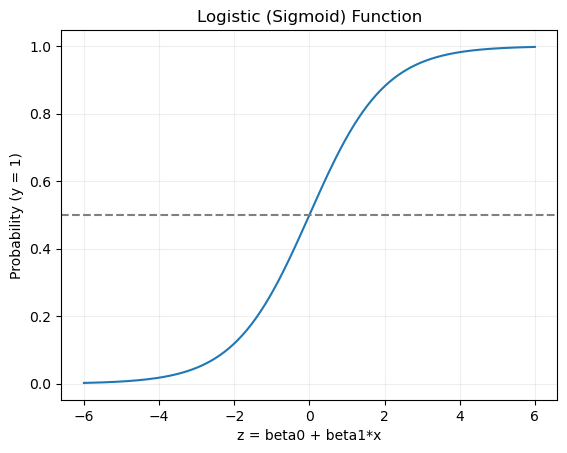

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

z = np.linspace(-6, 6, 200)
p = 1 / (1 + np.exp(-z))

plt.plot(z, p)
plt.axhline(0.5, linestyle='--', color='gray')
plt.xlabel('z = beta0 + beta1*x')
plt.ylabel('Probability (y = 1)')
plt.title('Logistic (Sigmoid) Function')
plt.grid(alpha=0.2)
plt.show()

**Your turn (3 min).** What happens to the probability when $z=0$? What happens when $z$ is a very large positive or negative number?

In [11]:
# TODO: Try z = -2, 0, and 2.
z_value = 0
probability = 1 / (1 + np.exp(-z_value))
print('z =', z_value, '  Probability =', round(probability, 4))

z = 0   Probability = 0.5


In [ ]:
## if z is NEGATIVE, then p is less than 0.5
## if z is POSITIVE, then p is more than 0.5

In [12]:
## What exactly is z?
#### in logistic regression z is the result (yhat) of a regression model

## Why not call it yhat?
#### because the logit transform is used in other models (neural nets -- activation functions)

### 2. Read the loan-default data

We use the same `default.csv` (`balance`, `default`) example as the introductory lecture. The course GitHub CSV is tried first. If it cannot be reached, the ZIP includes **simulated practice data** with the same columns so you can still complete the exercises; results will differ from the lecture slides.

In [13]:
url = 'https://raw.githubusercontent.com/martinwg/ISA591/refs/heads/main/data/default.csv'

df = pd.read_csv(url)[['balance', 'default']]
df.head()

,balance,default
0,729.526495,0
1,817.180407,0
2,1073.549164,0
3,529.250605,0
4,785.655883,0


In [14]:
## PROBLEM: we want the predict the PROBABILITY OF DEFAULT
#### x = balance past-due
#### y = {1: defaults, 0: does not}

**Your turn (5 min).** Inspect the number of observations, missing values, and the distribution of the target `default`. Is the target balanced?

In [16]:
## DISTRIBUTION
#### IMBALANCED (3.3% defaults, 96.7% non-defauts)
df['default'].value_counts() / len(df)

default
0    0.9667
1    0.0333
Name: count, dtype: float64

In [ ]:
## OBS (NO MISSING VALUES)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   balance  10000 non-null  float64
 1   default  10000 non-null  int64  
dtypes: float64(1), int64(1)
memory usage: 156.4 KB


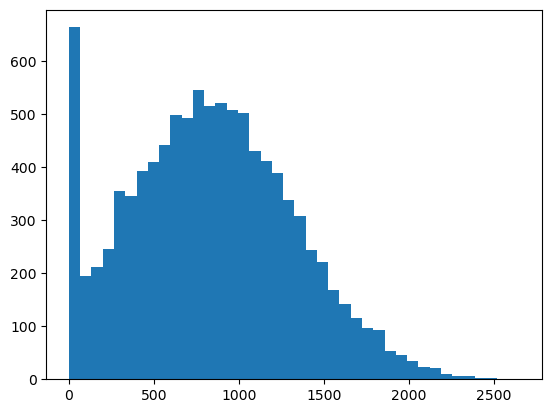

In [20]:
## HISTOGRAM
plt.hist(df['balance'], bins = 40);

### 3. Visualize the binary response

Each dot is either 0 or 1. A smooth probability curve will be more informative than trying to predict the binary response with a straight line.

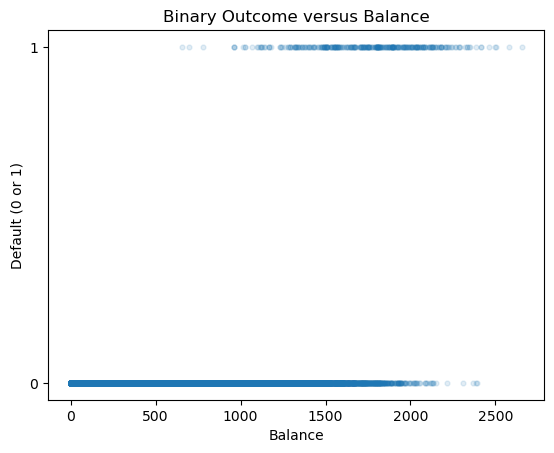

In [21]:
plt.scatter(df['balance'], df['default'], alpha=0.13, s=12)
plt.xlabel('Balance')
plt.ylabel('Default (0 or 1)')
plt.title('Binary Outcome versus Balance')
plt.yticks([0, 1])
plt.show()

In [23]:
## why NOT fit a linear regression; default = B0 + B1 balance
####  assumptions WON'T hold
####  predictions WILL be unconstrained (go below 0, above 1)

## what is the difference in LOGISTIC REGRESSION?
#### the model will be fit using the LOGIT TRANSFORMATION
#### the output will look like linear regression (y-intercept and slopes), p-values, statistical measures, we can transform to probabilities

## can we explain relationships?
#### yes, but the explanations will differ

### 4. Fit a descriptive logistic regression

`statsmodels` provides coefficients, p-values, and model-fit statistics. As in the course examples, add a constant (intercept) column to `X`.

In [25]:
## FOR DESCRIPTIVE MODELING
#### we will use statsmodels module (will include p-values, statistics)

#### IMPORT
import statsmodels.api as sm   ## NOT SKLEARN
from statsmodels.api import Logit 

#### INSTANCE
#### lr = Logit(y, X)   or
#### lr = sm.Logit(y, X) 
#### X must be a model matrix ----- X = [1, x1, x2, ..., xp]
#### lr = sm.Logit(y, sm.add_constant(X))

#### FIT
#### lr.fit() 

#### COMBINING INSTANCE And fit
#### lr = sm.Logit(y, add.constant(X)).fit()

In [26]:
import statsmodels.api as sm

X = df[['balance']]
y = df['default']

lr = sm.Logit(y, sm.add_constant(X)).fit()
print(lr.summary())

Optimization terminated successfully.
         Current function value: 0.079823
         Iterations 10
                           Logit Regression Results                           
Dep. Variable:                default   No. Observations:                10000
Model:                          Logit   Df Residuals:                     9998
Method:                           MLE   Df Model:                            1
Date:                Wed, 11 Nov 2026   Pseudo R-squ.:                  0.4534
Time:                        11:06:29   Log-Likelihood:                -798.23
converged:                       True   LL-Null:                       -1460.3
Covariance Type:            nonrobust   LLR p-value:                6.233e-290
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        -10.6513      0.361    -29.491      0.000     -11.359      -9.943
balance        0.0055      0

In [ ]:
## model fit is called lr
lr.params  ## y-int and slope

const     -10.651331
balance     0.005499
dtype: float64

In [29]:
## summary is MEANT to look like a R reg output
print(lr.summary())

                           Logit Regression Results                           
Dep. Variable:                default   No. Observations:                10000
Model:                          Logit   Df Residuals:                     9998
Method:                           MLE   Df Model:                            1
Date:                Wed, 11 Nov 2026   Pseudo R-squ.:                  0.4534
Time:                        11:09:03   Log-Likelihood:                -798.23
converged:                       True   LL-Null:                       -1460.3
Covariance Type:            nonrobust   LLR p-value:                6.233e-290
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        -10.6513      0.361    -29.491      0.000     -11.359      -9.943
balance        0.0055      0.000     24.952      0.000       0.005       0.006

Possibly complete quasi-separation: A fraction 0.13

In [ ]:
## you can save this model
import joblib

joblib.dump(lr, 'logistic_regression_model.joblib')

## you can read the model by using
## lr = joblib.load('logistic_regression_model.joblib')

['logistic_regression_model.joblib']

**Discuss (5 min).** Locate `const` and `balance` in the results. Which coefficient determines whether the predicted probability increases or decreases with balance? What does the p-value for `balance` test?

In [31]:
# Display estimated coefficients (avoid copying numbers from a slide).
print(lr.params)

beta0 = lr.params['const']
beta1 = lr.params['balance']

const     -10.651331
balance     0.005499
dtype: float64


### 5. Calculate log-odds, probability, and odds

The linear expression $z=\beta_0+\beta_1x$ is the **log-odds**. Convert it to probability with the logistic transformation. Convert probability to **odds** using $p/(1-p)$.

In [34]:
# Example: What is the probability of default for a $1,500 past-due balance?

#### step 1) compute z (reg output)
z = beta0 + beta1*1500
print(f'Prediction (Log-odds of default) is {z}')

#### step 2) compute p (logit transform)
p = 1 / (1+exp(-z))
print(f'The probability of default is {p}')

Prediction (Log-odds of default) is -2.4029552186010186
The probability of default is 0.08294762371431255


**Your turn (10 min).** Change the balance to 2,000 and then 1,937. Which has the largest probability of default? What does an odds value greater than 1 mean?

In [37]:
# TODO: Change this balance, rerun, and interpret the output.

### 1) compute prob(default) for a past-due balance of $2000
print(f'The probability of default is {1 / (1+exp(-(beta0 + beta1*2000)))}')

### 1) compute prob(default) for a past-due balance of $1937
print(f'The probability of default is {1 / (1+exp(-(beta0 + beta1*1937)))}')

The probability of default is 0.5857693698313319
The probability of default is 0.5000178704880684


In [ ]:
## z is the LOG(ODDS) of default

#### ODDS (prob / (1 - prob))
#### e.g., prob = 0.5   ---- odds = 0.5 / 0.5 = 1  ---- 1 to 1 odds of default
#### e.g., prob = 0.59  ---- odds = 0.59 / 0.41 = 1.44
0.59 / 0.41

1.4390243902439024

### 6. Plot the model's predicted probabilities

A probability curve helps us visualize what the logistic regression learned.

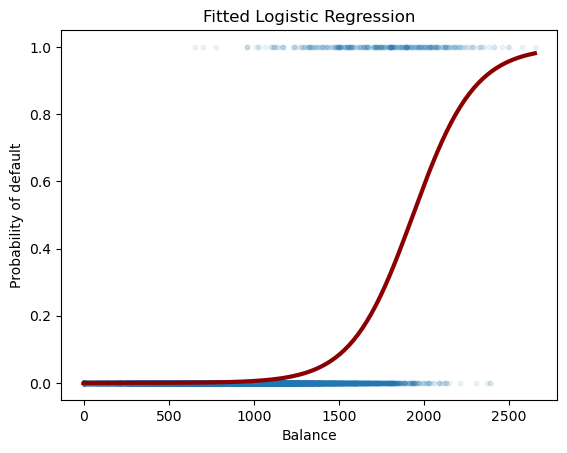

In [39]:
balance_grid = np.linspace(df['balance'].min(), df['balance'].max(), 200)
X_grid = pd.DataFrame({'balance': balance_grid})
p_grid = lr.predict(sm.add_constant(X_grid))

plt.scatter(df['balance'], df['default'], alpha=0.08, s=10)
plt.plot(balance_grid, p_grid, color='darkred', linewidth=3)
plt.xlabel('Balance')
plt.ylabel('Probability of default')
plt.title('Fitted Logistic Regression')
plt.show()

### 7. Interpret a coefficient as an odds ratio

A one-unit increase in $x$ multiplies the **odds** by $e^{\beta_1}$. A change of 100 balance units multiplies the odds by $e^{100\beta_1}$. This is **not** a fixed increase in probability.

In [ ]:
## how about the interpretation of THE SLOPE
#### y-intercept
#### slope = 0.005 

#### As balance past-due increases by $1, the LOG(ODDS) of default increase by 0.005
exp(0.005)
#### As balance past-due increases by $1, the ODDS of default CHANGE BY A FACTOR of 1.005 (increases by0.5%)

1.005012520859401

In [43]:
print('Odds ratio for +$1 of balance:', round(np.exp(beta1), 4))
print('Odds ratio for +$100 of balance:', round(np.exp(beta1 * 100), 4))

Odds ratio for +$1 of balance: 1.0055
Odds ratio for +$100 of balance: 1.7331


**Exit ticket (5 min).** Explain in one sentence each: *probability*, *odds*, and *log-odds*. Why is it wrong to say the coefficient `balance` is a constant change in probability?